Shortest Path:
A → C → B → D → E

Total Cost:
10

A* Calculation Table:


,Node,g(n),h(n),f(n)
0,A,0,7,7
1,C,2,4,6
2,B,3,5,8
3,B,3,5,8
4,D,8,2,10
5,E,10,0,10


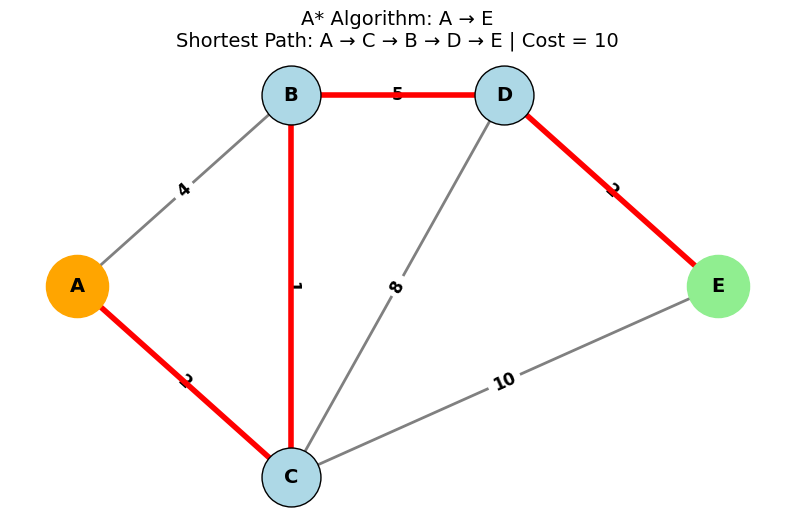

In [ ]:
import heapq
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

graph = {
    'A': [('B', 4), ('C', 2)],
    'B': [('A', 4), ('C', 1), ('D', 5)],
    'C': [('A', 2), ('B', 1), ('D', 8), ('E', 10)],
    'D': [('B', 5), ('C', 8), ('E', 2)],
    'E': [('C', 10), ('D', 2)]
}

heuristic = {
    'A': 7,
    'B': 5,
    'C': 4,
    'D': 2,
    'E': 0
}

def a_star(graph, start, goal, heuristic):
    open_list = []
    heapq.heappush(open_list, (0, start))

    g_cost = {start: 0}
    parent = {start: None}
    table = []

    while open_list:
        f, current = heapq.heappop(open_list)

        g = g_cost[current]
        h = heuristic[current]

        table.append({
            "Node": current,
            "g(n)": g,
            "h(n)": h,
            "f(n)": g + h
        })

        if current == goal:
            path = []

            while current is not None:
                path.append(current)
                current = parent[current]

            path.reverse()

            return path, g_cost[goal], pd.DataFrame(table)

        for neighbor, weight in graph[current]:
            new_g = g_cost[current] + weight

            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                f = new_g + heuristic[neighbor]

                heapq.heappush(
                    open_list,
                    (f, neighbor)
                )

                parent[neighbor] = current

    return None, None, pd.DataFrame(table)


start = 'A'
goal = 'E'

path, cost, table = a_star(
    graph,
    start,
    goal,
    heuristic
)

print("Shortest Path:")
print(" → ".join(path))

print("\nTotal Cost:")
print(cost)

print("\nA* Calculation Table:")
display(table)

G = nx.Graph()

for node in graph:
    for neighbor, weight in graph[node]:
        G.add_edge(node, neighbor, weight=weight)

pos = {
    'A': (0, 1),
    'B': (2, 2),
    'C': (2, 0),
    'D': (4, 2),
    'E': (6, 1)
}

plt.figure(figsize=(10, 6))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color='lightblue',
    node_size=1800,
    edgecolors='black'
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color='gray',
    width=2
)

edge_labels = nx.get_edge_attributes(
    G,
    'weight'
)

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=12,
    font_weight='bold'
)

path_edges = list(zip(path, path[1:]))

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=path_edges,
    edge_color='red',
    width=4
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=[start],
    node_color='orange',
    node_size=2000
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=[goal],
    node_color='lightgreen',
    node_size=2000
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=14,
    font_weight='bold'
)

plt.title(
    f"A* Algorithm: {start} → {goal}\n"
    f"Shortest Path: {' → '.join(path)} | Cost = {cost}",
    fontsize=14
)

plt.axis('off')
plt.show()